# Sparse Retrieval: from BM25 to SPLADE — Practical Lab

---
## Block 0 · Setup

In [ ]:
!pip -q install "sentence-transformers>=5.4.1" nltk datasets

In [16]:
import re, math
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch

pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 40)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


### A toy corpus
Six short documents and one query. Only **D0** really answers the query.

In [17]:
DOCS = [
    "Per sistemare una foratura della ruota di una bicicletta: smonta la camera d'aria, individua il buco, applica la toppa e rigonfiala.",  # D0 relevant (zero shared words with the query)
    "L'auto aveva una gomma a terra, così ci siamo fermati alla stazione di servizio per controllarla.",                                    # D1 decoy: same words, wrong vehicle
    "Il team ripara il bug della pagina di login prima del rilascio.",                                                                      # D2 decoy: shares "ripara"
    "La gomma da cancellare morbida toglie la matita senza rovinare la carta.",                                                             # D3 decoy: "gomma" with a different meaning
    "Il tempo a Roma sarà soleggiato per tutta la settimana.",                                                                              # D4 unrelated
    "La pressione delle gomme va controllata una volta al mese su ogni automobile.",                                                        # D5 decoy: right topic, wrong vehicle, plural "gomme"
]
DOC_IDS = [f"D{i}" for i in range(len(DOCS))]
QUERY = "Come si ripara una gomma a terra sulla bici?"


---
## Block 1 · BM25 and the vocabulary mismatch problem

### 1.1 Tokenization
BM25 works on **words**: lowercase, split, drop stopwords (very common words that carry little meaning).

In [18]:
STOPWORDS = {"a", "al", "alla", "aveva", "ci", "come", "così", "d", "da", "del", "della", "delle",
             "di", "e", "il", "io", "l", "la", "mi", "mia", "ogni", "per", "prima", "sarà",
             "senza", "si", "siamo", "su", "sulla", "tutta", "un", "una", "va", "volta"}

def tokenize(text):
    # accented letters must be in the character class, otherwise "così" -> "cos" and "sarà" -> "sar"
    return [w for w in re.findall(r"[a-zàèéìòù]+", text.lower()) if w not in STOPWORDS]

doc_tokens = [tokenize(d) for d in DOCS]
query_tokens = tokenize(QUERY)

for i, toks in zip(DOC_IDS, doc_tokens):
    print(f"{i}: {toks}")
print(f"\nQUERY: {query_tokens}")


D0: ['sistemare', 'foratura', 'ruota', 'bicicletta', 'smonta', 'camera', 'aria', 'individua', 'buco', 'applica', 'toppa', 'rigonfiala']
D1: ['auto', 'gomma', 'terra', 'fermati', 'stazione', 'servizio', 'controllarla']
D2: ['team', 'ripara', 'bug', 'pagina', 'login', 'rilascio']
D3: ['gomma', 'cancellare', 'morbida', 'toglie', 'matita', 'rovinare', 'carta']
D4: ['tempo', 'roma', 'soleggiato', 'settimana']
D5: ['pressione', 'gomme', 'controllata', 'mese', 'automobile']

QUERY: ['ripara', 'gomma', 'terra', 'bici']


### 1.2 The BM25 representation
For each document and each term $t$, BM25 computes a weight:

$$w(t, d) = \text{IDF}(t)\cdot\frac{tf(t,d)\,(k_1+1)}{tf(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}
\qquad \text{IDF}(t)=\ln\left(1+\frac{N-n_t+0.5}{n_t+0.5}\right)$$

- $tf$: how many times $t$ appears in $d$ 
- $n_t$: how many documents contain $t$ 
- $N$: number of documents
- $|d|$: document length · avgdl: average length · $k_1$, $b$: parameters (typically 1.2 and 0.75)

In [19]:
class BM25:
    """A minimal BM25 class."""

    def __init__(self, tokenized_docs, k1=1.2, b=0.75):
        # k1 controls term-frequency saturation: higher = repeated terms keep adding score longer
        # b  controls length normalization: 0 = ignore document length, 1 = fully normalize by it
        self.k1, self.b = k1, b

        self.docs = tokenized_docs                    # list of documents, each a list of tokens
        self.N = len(tokenized_docs)                  # number of documents in the collection
        self.avgdl = np.mean([len(d) for d in tokenized_docs])   # average document length in tokens

        # vocabulary = every distinct token in the collection (sorted so columns are stable)
        self.vocab = sorted({t for d in tokenized_docs for t in d})

        # document frequency: in how many documents each term appears at least once
        # (set(d) so a term repeated within one document is counted only once)
        df = Counter(t for d in tokenized_docs for t in set(d))            # n_t: documents containing t

        # IDF: rare terms get a high weight, terms in almost every document get a weight near 0
        # idf(t) = ln(1 + (N - n_t + 0.5) / (n_t + 0.5)); the +1 keeps it non-negative
        self.idf = {t: math.log(1 + (self.N - df[t] + 0.5) / (df[t] + 0.5)) for t in self.vocab}

    def term_weight(self, t, doc):
        """BM25 weight of term t in one document (0 if the term is absent)."""
        tf = doc.count(t)                             # raw count of t in this document
        if tf == 0 or t not in self.idf:              # absent or unseen term contributes nothing
            return 0.0

        # length normalization factor: grows for documents longer than average, shrinks for shorter ones
        norm = self.k1 * (1 - self.b + self.b * len(doc) / self.avgdl)     # length normalization

        # saturated TF x IDF:
        #   tf * (k1 + 1) / (tf + norm)  rises with tf but flattens out toward k1 + 1
        return self.idf[t] * tf * (self.k1 + 1) / (tf + norm)              # saturated TF x IDF

    def matrix(self):
        """Documents x vocabulary table of BM25 weights."""
        # one row per document, one column per vocabulary term; most cells are 0
        # (a sparse matrix stored densely, which is fine for a small teaching collection)
        return pd.DataFrame([[self.term_weight(t, d) for t in self.vocab] for d in self.docs],
                            columns=self.vocab)

    def score(self, query_tokens, doc):
        """Relevance of a document to a query: sum of the weights of the query terms in the document."""
        # a query term repeated in the query is counted each time it appears
        return sum(self.term_weight(t, doc) for t in query_tokens)

bm25 = BM25(doc_tokens)                               # compute N, avgdl, vocabulary and IDF once
W = bm25.matrix()                                     # full document-term weight table
W.index = DOC_IDS                                     # label rows with document ids instead of 0..N-1

print(f"{W.shape[0]} documents x {W.shape[1]} vocabulary terms · "
      f"{(W > 0).values.mean():.0%} of the cells are non-zero")

# heatmap of the table: darker green = higher weight; axis=None scales colors over the whole table
# (not per row or column), and zeros are shown as blank cells so the nonzero ones stand out
W.style.background_gradient(cmap="Greens", axis=None).format(lambda v: f"{v:.2f}" if v else "")


6 documents x 40 vocabulary terms · 17% of the cells are non-zero


,applica,aria,auto,automobile,bicicletta,buco,bug,camera,cancellare,carta,controllarla,controllata,fermati,foratura,gomma,gomme,individua,login,matita,mese,morbida,pagina,pressione,rigonfiala,rilascio,ripara,roma,rovinare,ruota,servizio,settimana,sistemare,smonta,soleggiato,stazione,team,tempo,terra,toglie,toppa
D0,1.18,1.18,,,1.18,1.18,,1.18,,,,,,1.18,,,1.18,,,,,,,1.18,,,,,1.18,,,1.18,1.18,,,,,,,1.18
D1,,,1.53,,,,,,,,1.53,,1.53,,1.02,,,,,,,,,,,,,,,1.53,,,,,1.53,,,1.53,,
D2,,,,,,,1.62,,,,,,,,,,,1.62,,,,1.62,,,1.62,1.62,,,,,,,,,,1.62,,,,
D3,,,,,,,,,1.53,1.53,,,,,1.02,,,,1.53,,1.53,,,,,,,1.53,,,,,,,,,,,1.53,
D4,,,,,,,,,,,,,,,,,,,,,,,,,,,1.86,,,,1.86,,,1.86,,,1.86,,,
D5,,,,1.73,,,,,,,,1.73,,,,1.73,,,,1.73,,,1.73,,,,,,,,,,,,,,,,,


Each **row is a sparse vector over the vocabulary**: a document only activates the words it contains.
Keep this picture in mind: SPLADE will produce exactly this kind of vector.

### 1.3 IDF: rare words weigh more

In [5]:
idf = pd.Series(bm25.idf).sort_values()
print("Most common terms (low IDF):\n", idf.head(4).round(2).to_string())
print("\nRarest terms (high IDF):\n", idf.tail(4).round(2).to_string())

Most common terms (low IDF):
 gomma      1.03
applica    1.54
auto       1.54
aria       1.54

Rarest terms (high IDF):
 tempo     1.54
terra     1.54
toglie    1.54
toppa     1.54


### 1.4 TF saturation and length normalization
🔮 **Predict:** if a word appears 20 times instead of once, is the document 20 times more relevant?

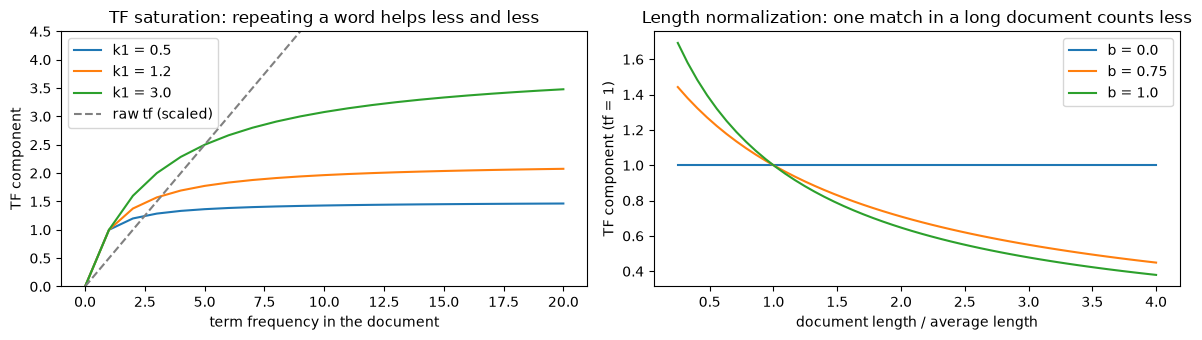

In [ ]:
tfs = np.arange(0, 21)                     # term frequencies to plot: the term appears 0..20 times
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))

# BM25 uses the "TF component":
# k1 sets how fast the curve flattens:
#   - small k1 (0.5): saturates almost immediately; after a few occurrences more repeats add nothing
#   - large k1 (3.0): grows for longer, closer to a linear count
for k1 in [0.5, 1.2, 3.0]:                 # 1.2 is the usual default
    ax1.plot(tfs, [tf * (k1 + 1) / (tf + k1) for tf in tfs], label=f"k1 = {k1}")

# Reference: a linear score in tf (halved so it fits the same axis). Shows what we'd get without
# saturation: every extra occurrence would be worth the same as the first.
ax1.plot(tfs, tfs / 2, "--", c="gray", label="raw tf (scaled)")
ax1.set_xlabel("term frequency in the document"); ax1.set_ylabel("TF component"); ax1.set_ylim(0, 4.5)
ax1.set_title("TF saturation: repeating a word helps less and less"); ax1.legend()

# a long document has more words, so it is more likely to contain a query term by chance.
# One match in a short, focused document says more than one match in a long one, so BM25
# lowers the weight of a match in documents longer than average and raises it in shorter ones.

ratios = np.linspace(0.25, 4, 50)                                           # |d| / avgdl
for b in [0.0, 0.75, 1.0]:
    k1 = 1.2
    ax2.plot(ratios, [(k1 + 1) / (1 + k1 * (1 - b + b * r)) for r in ratios], label=f"b = {b}")
ax2.set_xlabel("document length / average length"); ax2.set_ylabel("TF component (tf = 1)")
ax2.set_title("Length normalization: one match in a long document counts less"); ax2.legend()
plt.tight_layout(); plt.show()


### 1.5 The inverted index
The same table, read **by columns**: for every term, the documents that contain it.
At query time we only touch the lists of the query terms, not the whole collection: this is why BM25 is fast.

In [11]:
inverted_index = {t: [(DOC_IDS[i], round(w, 2)) for i, w in enumerate(W[t]) if w > 0] for t in W.columns}

for t in ["gomma", "ripara", "automobile", "ruota"]:
    print(f"{t:>6} -> {inverted_index.get(t, [])}")

 gomma -> [('D1', 1.02), ('D3', 1.02)]
ripara -> [('D2', 1.62)]
automobile -> [('D5', 1.73)]
 ruota -> [('D0', 1.18)]


### 1.6 Scoring the query
The query is also a vector over the vocabulary, but **binary**: a term is either in the query or not.
Score = sum of the document's weights for the query terms.

🔮 **Predict:** which document wins? What is the score of D0, the only relevant one?

In [12]:
def bm25_ranking(query_tokens):
    rows = []
    for i, doc in zip(DOC_IDS, bm25.docs):
        contributions = {t: round(bm25.term_weight(t, doc), 2) for t in query_tokens if bm25.term_weight(t, doc) > 0}
        rows.append({"doc": i, "BM25 score": bm25.score(query_tokens, doc), "matched terms": contributions,
                     "text": DOCS[DOC_IDS.index(i)][:60]})
    return pd.DataFrame(rows).sort_values("BM25 score", ascending=False).reset_index(drop=True)

print("query terms:", query_tokens)
bm25_ranking(query_tokens)

query terms: ['ripara', 'gomma', 'terra', 'bici']


,doc,BM25 score,matched terms,text
0,D1,2.54,"{'gomma': 1.02, 'terra': 1.53}","L'auto aveva una gomma a terra, così ci siamo ..."
1,D2,1.62,{'ripara': 1.62},Il team ripara il bug della pagina di login pr...
2,D3,1.02,{'gomma': 1.02},La gomma da cancellare morbida toglie la matit...
3,D0,0.00,{},Per sistemare una foratura della ruota di una ...
4,D4,0.00,{},Il tempo a Roma sarà soleggiato per tutta la s...
5,D5,0.00,{},La pressione delle gomme va controllata una vo...


### 1.7 The vocabulary mismatch problem
D0 is the answer, but it scores **0**: it says *repairing / punctured / bicycle / wheel*, the query says *fix / flat / bike / tire*.
Look at the representation: the query's columns and D0's columns **do not overlap at all**.

In [13]:
cols = query_tokens + [t for t in doc_tokens[0] if t not in query_tokens]
view = W.reindex(columns=cols, fill_value=0).loc[["D0"]]
view.loc["QUERY"] = [1 if t in query_tokens else 0 for t in cols]
view.style.background_gradient(cmap="Greens", axis=None).format(lambda v: f"{v:.2f}" if v else "")

,ripara,gomma,terra,bici,sistemare,foratura,ruota,bicicletta,smonta,camera,aria,individua,buco,applica,toppa,rigonfiala
D0,,,,,1.18,1.18,1.18,1.18,1.18,1.18,1.18,1.18,1.18,1.18,1.18,1.18
QUERY,1.00,1.00,1.00,1.00,,,,,,,,,,,,


Stemming fixes *tire / tires* or *repair / repairing*, but **not synonyms**: *fix* ≠ *repair*, *bike* ≠ *bicycle*.

**The question for the next block:** what if the vector could also activate words that are **not in the text**?

---
## Block 2 · How SPLADE works

**SPLADE** (SParse Lexical AnD Expansion) produces the same object as BM25, a sparse vector over a vocabulary
(BERT's 30,522 WordPiece tokens), with two differences:
- the weights are **learned**, not computed with a formula
- the vector can activate **expansion terms**: words that are not in the text but are related to it

The trick: reuse the **masked language modeling (MLM) head** of BERT.

### 2.1 The MLM head already knows related words
🔮 **Predict:** what will BERT put in the blank?

In [14]:
from transformers import pipeline

# Fill-mask pipeline: loads BERT with its masked-language-model head.
# For each [MASK] position the model scores every vocabulary term.
fill = pipeline("fill-mask", model="dbmdz/bert-base-italian-xxl-uncased", device=device)

# Predict the missing word. the model expects the literal "[MASK]" token.
# top_k=8 returns the 8 most probable replacements, ordered from most to least likely.
for p in fill("Devo riparare la [MASK] della mia bisicletta.", top_k=8):
    # p["token_str"]: the predicted word; p["score"]: its probability after softmax
    # (scores over the full vocabulary sum to 1, so these 8 are a subset)
    # {:>10} right-aligns the word in a 10-character column so the scores line up
    print(f"{p['token_str']}  {p['score']:.3f}")


/home/lpozzi/Git/data-science-lectures/ir/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10350.11it/s]
BertForMaskedLM LOAD REPORT from: dbmdz/bert-base-italian-xxl-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


macchina  0.190
bici  0.061
casa  0.061
carrozzeria  0.042
faccia  0.038
bicicletta  0.036
borsa  0.033
moto  0.028


The MLM head gives a score to **every word in the vocabulary**, at **every position**, not only at `[MASK]`.
Let's look at what it predicts for each token of the query.

In [16]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

bert_tok = AutoTokenizer.from_pretrained("dbmdz/bert-base-italian-xxl-uncased")
bert_mlm = AutoModelForMaskedLM.from_pretrained("dbmdz/bert-base-italian-xxl-uncased").to(device).eval()

inputs = bert_tok(QUERY, return_tensors="pt").to(device)
with torch.no_grad():
    logits = bert_mlm(**inputs).logits                    # (batch, tokens, vocabulary)
print("MLM logits shape:", tuple(logits.shape), "-> one score per vocabulary word, for each token\n")

for pos, tok_id in enumerate(inputs.input_ids[0]):
    top = logits[0, pos].topk(6).indices
    print(f"{bert_tok.decode([tok_id]):>8} -> {bert_tok.convert_ids_to_tokens(top)}")

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 11490.15it/s]
BertForMaskedLM LOAD REPORT from: dbmdz/bert-base-italian-xxl-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MLM logits shape: (1, 12, 32102) -> one score per vocabulary word, for each token

   [CLS] -> ['?', '.', 'tutto', 'guida', '!', '[UNK]']
    come -> ['come', 'com', '##come', 'como', 'quando', 'non']
      si -> ['si', 'mi', 'funziona', 's', 'fa', 'ti']
  ripara -> ['ripara', 'riparare', 'aggiusta', 'trova', 'monta', 'toglie']
     una -> ['una', 'la', 'un', '1', 'une', 'alla']
   gomma -> ['gomma', 'ruota', 'pneumatico', 'bicicletta', 'gomme', 'bici']
       a -> ['a', 'in', 'di', 'per', 'caduta', 'si']
   terra -> ['terra', 'pavimento', 'neve', 'suolo', 'casa', 'bordo']
   sulla -> ['sulla', 'alla', 'della', 'dalla', 'sulle', 'nella']
    bici -> ['bici', 'bicicletta', 'bike', 'batteria', 'biciclette', 'tua']
       ? -> ['?', '.', '!', '[UNK]', 'senza', ',']
   [SEP] -> ['.', ',', 'una', 'su', "'", '?']


For the token *bike* the head also scores *bicycle*, *car*…: the **expansion** comes for free.
SPLADE turns these (tokens × vocabulary) scores into **one** vector per text.

### 2.2 Sparse tensors
A vocabulary-sized vector is huge (30k–250k dimensions) but almost all zeros, so we store only the non-zero entries.

In [17]:
import torch

dense = torch.tensor([
  [0.0, 0.0, 1.7, 0.0, 0.0, 2.3],
  [0.0, 5.1, 0.0, 0.0, 0.0, 0.0]
])
sp = dense.to_sparse()

print(sp.indices())      # row/col of each nonzero
print(sp.values())       # the nonzero values

sparse = dense.to_sparse()
print(sparse)
print(f"\nstored values: {sparse._nnz()} instead of {dense.numel()}")

tensor([[0, 0, 1],
        [2, 5, 1]])
tensor([1.7000, 2.3000, 5.1000])
tensor(indices=tensor([[0, 0, 1],
                       [2, 5, 1]]),
       values=tensor([1.7000, 2.3000, 5.1000]),
       size=(2, 6), nnz=3, layout=torch.sparse_coo)

stored values: 3 instead of 12


### 2.3 SPLADE pooling: from (tokens × vocabulary) to one vector
`SpladePooling` from sentence-transformers applies three operations to the MLM logits:
1. **ReLU**: keep only positive evidence
2. **log1p**: damp large values (the same idea as BM25's TF saturation)
3. **max over tokens**: one score per vocabulary word, the strongest across the text

A toy example: 1 text, 3 token positions, a vocabulary of 4 words.

🔮 **Predict:** token 3 has logits of 10 everywhere, but it is **padding** (`attention_mask = 0`). Does it affect the result?

In [18]:
from sentence_transformers.sparse_encoder.modules import SpladePooling

pool = SpladePooling(pooling_strategy="max", activation_function="relu")
pool.eval()

features = {
    "token_embeddings": torch.tensor([
        [  # batch item 0, shape (3 tokens, 4 vocabulary words)
            [ 1.0, -1.0,  0.0, 2.0],   # token 1 logits
            [ 0.5,  3.0, -2.0, 1.0],   # token 2 logits
            [10.0, 10.0, 10.0, 10.0],  # token 3 logits, but masked out below
        ]
    ]),
    "attention_mask": torch.tensor([[1, 1, 0]]),
}
print("max pooling:", pool(features)["sentence_embedding"])

max pooling: tensor([[0.6931, 1.3863, 0.0000, 1.0986]])


In [19]:
print(torch.expm1(pool(features)["sentence_embedding"]))


tensor([[1., 3., 0., 2.]])


### The formula behind the code
With MLM logits $L \in \mathbb{R}^{B\times T\times V}$ and attention mask $M \in \{0,1\}^{B\times T}$:

$$S_{b,v} = \max_{t} \; \log\big(1 + \text{ReLU}(L_{b,t,v} \cdot M_{b,t})\big)$$

(sum pooling replaces $\max_t$ with $\sum_t$). The result $S \in \mathbb{R}^{B\times V}$ has one weight per vocabulary word,
and every word with no positive evidence stays exactly **0**.

---
## Block 3 · The same example with SPLADE

Same corpus, same query, same steps as Block 1. Model: [`naver/splade-cocondenser-ensembledistil`](https://huggingface.co/naver/splade-cocondenser-ensembledistil), a BERT-base SPLADE model trained on MS MARCO.

### 3.1 Encode queries and documents
Queries and documents have separate methods, because some sparse models encode them differently.

In [1]:
from sentence_transformers import SparseEncoder
splade = SparseEncoder("lopozz/splade-bert-base-italian-xxl-uncased", device='cuda')

/home/lpozzi/Git/data-science-lectures/ir/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
This model was created with Sentence Transformers version 5.6.0, but you're using version 5.4.1. Consider updating to the latest version to avoid potential issues.
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 9898.47it/s]


In [6]:
tok = splade.tokenizer
texts = ['Ciao come va', 'Buongiorno come sta']
features = splade.preprocess(texts)
embeddings = splade(features)

In [7]:
emb = embeddings["sentence_embedding"].detach()

print("shape:", emb.shape)                       # (batch, vocab_size)
print("active dims per text:", (emb > 0).sum(dim=1).tolist())
print("sparsity:", 1 - (emb > 0).float().mean(dim=1))

shape: torch.Size([2, 31102])
active dims per text: [48, 71]
sparsity: tensor([0.9985, 0.9977])


### Which input token produced each term?

Max pooling throws away the token that "won" each vocabulary dimension, so it cannot be recovered from the sentence vector alone. We can recompute it from `token_embeddings`: apply the same mask, ReLU and `log1p`, then take `argmax` over the token axis instead of `max`.

When the winning input token is *different* from the term itself, that is **term expansion**: the model activated a related word that was not in the text.

In [8]:
import torch

token_logits = embeddings["token_embeddings"].detach()      # (B, T, V)
mask = embeddings["attention_mask"].unsqueeze(-1)            # (B, T, 1)

# same transformation SpladePooling applies, but we keep the token dimension
acts = torch.log1p(torch.relu(token_logits * mask))          # (B, T, V)
_, winner = acts.max(dim=1)                                  # (B, V): index of the winning token

input_tokens = [tok.convert_ids_to_tokens(ids) for ids in embeddings["input_ids"]]

for b, text in enumerate(texts):
    print(f"\n{text!r}  ->  {input_tokens[b]}")
    vals, ids = emb[b].topk(10)
    for v, i in zip(vals, ids):
        t = winner[b, i].item()
        print(f"  {tok.convert_ids_to_tokens(i.item()):>15}  {v.item():.3f}   from input token {t} ({input_tokens[b][t]})")


'Ciao come va'  ->  ['[CLS]', 'ciao', 'come', 'va', '[SEP]']
               va  2.667   from input token 3 (va)
             ciao  2.538   from input token 1 (ciao)
            andra  2.104   from input token 3 (va)
           andata  2.034   from input token 3 (va)
           andare  1.937   from input token 3 (va)
             come  1.930   from input token 2 (come)
          andando  1.700   from input token 3 (va)
             vada  1.668   from input token 3 (va)
           andato  1.635   from input token 3 (va)
            vanno  1.634   from input token 3 (va)

'Buongiorno come sta'  ->  ['[CLS]', 'buongiorno', 'come', 'sta', '[SEP]']
       buongiorno  2.907   from input token 1 (buongiorno)
              sta  2.248   from input token 3 (sta)
        buonasera  2.099   from input token 1 (buongiorno)
             ciao  1.930   from input token 1 (buongiorno)
            salve  1.619   from input token 1 (buongiorno)
       buonanotte  1.528   from input token 1 (buongiorno)
 

### 3.2 The SPLADE representation
The same documents × vocabulary table as Block 1, now with SPLADE weights (top 12 terms per document).

In [11]:
import pandas as pd 
DOCS = [
    "Per sistemare una foratura della ruota di una bicicletta: smonta la camera d'aria, individua il buco, applica la toppa e rigonfiala.",  # D0 relevant (zero shared words with the query)
    "L'auto aveva una gomma a terra, così ci siamo fermati alla stazione di servizio per controllarla.",                                    # D1 decoy: same words, wrong vehicle
    "Il team ripara il bug della pagina di login prima del rilascio.",                                                                      # D2 decoy: shares "ripara"
    "La gomma da cancellare morbida toglie la matita senza rovinare la carta.",                                                             # D3 decoy: "gomma" with a different meaning
    "Il tempo a Roma sarà soleggiato per tutta la settimana.",                                                                              # D4 unrelated
    "La pressione delle gomme va controllata una volta al mese su ogni automobile.",                                                        # D5 decoy: right topic, wrong vehicle, plural "gomme"
]
DOC_IDS = [f"D{i}" for i in range(len(DOCS))]
QUERY = "Come si ripara una gomma a terra sulla bici?"

doc_emb = splade.encode_document(DOCS)            # sparse tensor (documents, 30522)
q_emb = splade.encode_query([QUERY])              # sparse tensor (1, 30522)
print("documents:", tuple(doc_emb.shape), "· query:", tuple(q_emb.shape), "·", doc_emb.layout)

decoded_docs = splade.decode(doc_emb, top_k=12)   # list of [(token, weight), ...] per document
S = pd.DataFrame([dict(terms) for terms in decoded_docs], index=DOC_IDS).fillna(0)
S = S[S.max().sort_values(ascending=False).index]  # strongest terms first
print(f"{S.shape[1]} vocabulary terms in this view (top 12 per document)")
S.style.background_gradient(cmap="Purples", axis=None).format(lambda v: f"{v:.2f}" if v else "")

documents: (6, 31102) · query: (1, 31102) · torch.sparse_coo
63 vocabulary terms in this view (top 12 per document)


,bug,gomma,gomme,bicicletta,matita,auto,roma,pressione,login,tempo,ruota,bici,cancellare,carta,rilascio,pagina,automobile,pneumatici,biciclette,fora,ripara,morbida,macchina,pneumatico,riparare,buco,automobili,ruote,sistemare,cancella,pagine,bike,ciclismo,stazione,controllare,servizio,team,rilascia,##tura,controllata,rilasciato,penna,morbido,rovinare,controllo,terra,ciclisti,romani,cancellato,riparazione,controlla,sole,pennello,meteo,veicolo,rilasciati,romano,settimana,romana,rome,a,##roma,clima
D0,,,,3.15,,,,,,,2.95,2.92,,,,,,,2.80,2.80,,,,,,2.63,,2.57,2.56,,,2.52,2.50,,,,,,2.37,,,,,,,,2.31,,,,,,,,,,,,,,,,
D1,,3.19,2.89,,,3.07,,,,,,,,,,,,2.53,,,,,2.70,2.61,,,,,,,,,,2.45,2.28,2.40,,,,,,,,,,2.32,,,,,2.24,,,,2.19,,,,,,,,
D2,3.23,,,,,,,,2.99,,,,,,2.87,2.86,,,,,2.77,,,,2.63,,,,,,2.52,,,,,,2.40,2.40,,,2.36,,,,,,,,,2.24,,,,,,2.19,,,,,,,
D3,,3.03,2.53,,3.07,,,,,,,,2.91,2.88,,,,,,,,2.71,,,,,,,,2.55,,,,,,,,,,,,2.35,2.35,2.35,,,,,2.25,,,,2.22,,,,,,,,,,
D4,,,,,,,3.03,,,2.97,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,2.25,,,,2.23,,2.19,,,2.15,2.05,2.02,2.00,1.88,1.85,1.85
D5,,2.76,3.18,,,2.66,,3.00,,,,,,,,,2.82,2.81,,,,,2.36,2.66,,,2.61,,,,,,,,2.45,,,,,2.37,,,,,2.33,,,,,,,,,,,,,,,,,,


### 3.3 Inside one document: words in the text vs expansion terms
🔮 **Predict:** which words that are **not** in D0 will SPLADE activate?

In [12]:
def explain(text, is_query=False, top_k=20):
    """Top SPLADE terms of one text, marking which ones appear in it."""
    emb = splade.encode_query([text]) if is_query else splade.encode_document([text])
    in_text = set(splade.tokenizer.tokenize(text))
    rows = [{"term": t, "weight": w, "in text?": "yes" if t in in_text else "EXPANSION"}
            for t, w in splade.decode(emb, top_k=top_k)[0]]
    return pd.DataFrame(rows)

print("D0:", DOCS[0])
explain(DOCS[0])

D0: Per sistemare una foratura della ruota di una bicicletta: smonta la camera d'aria, individua il buco, applica la toppa e rigonfiala.


,term,weight,in text?
0,bicicletta,3.145288,yes
1,ruota,2.952339,yes
2,bici,2.923797,EXPANSION
3,biciclette,2.801491,EXPANSION
4,fora,2.799472,yes
5,buco,2.630958,yes
6,ruote,2.573393,EXPANSION
7,sistemare,2.557218,yes
8,bike,2.522677,EXPANSION
9,ciclismo,2.499557,EXPANSION


### 3.4 Inside the query
In BM25 the query vector was **binary**. In SPLADE it has **learned weights**, expansion terms,
and stopwords like *how* and *do* get low or zero weight.

In [13]:
print("QUERY:", QUERY)
explain(QUERY, is_query=True)

QUERY: Come si ripara una gomma a terra sulla bici?


,term,weight,in text?
0,gomma,1.318561,yes
1,terra,1.303237,yes
2,come,1.266992,yes
3,bici,1.200031,yes
4,ripara,1.141561,yes
5,una,1.028562,yes
6,sulla,1.017910,yes
7,a,0.872612,yes
8,si,0.754547,yes
9,?,0.442120,yes


### 3.5 Score and rank
Score = dot product between the query vector and each document vector (exactly like BM25: a sum over shared terms).

🔮 **Predict:** does D0 still score 0?

In [20]:
splade_scores = splade.similarity(q_emb, doc_emb)[0].cpu()
bm25_scores = {i: bm25.score(query_tokens, d) for i, d in zip(DOC_IDS, bm25.docs)}

ranking = pd.DataFrame({"doc": DOC_IDS,
                        "BM25 score": [bm25_scores[i] for i in DOC_IDS],
                        "SPLADE score": splade_scores.tolist(),
                        "text": [d[:60] for d in DOCS]})
ranking["BM25 rank"] = ranking["BM25 score"].rank(ascending=False, method="min").astype(int)
ranking["SPLADE rank"] = ranking["SPLADE score"].rank(ascending=False, method="min").astype(int)
ranking.sort_values("SPLADE score", ascending=False).reset_index(drop=True)

,doc,BM25 score,SPLADE score,text,BM25 rank,SPLADE rank
0,D1,2.54,11.39,"L'auto aveva una gomma a terra, così ci siamo ...",1,1
1,D0,0.00,10.90,Per sistemare una foratura della ruota di una ...,4,2
2,D3,1.02,6.56,La gomma da cancellare morbida toglie la matit...,3,3
3,D5,0.00,4.73,La pressione delle gomme va controllata una vo...,4,4
4,D2,1.62,3.17,Il team ripara il bug della pagina di login pr...,2,5
5,D4,0.00,1.64,Il tempo a Roma sarà soleggiato per tutta la s...,4,6


### 3.6 Why does D0 match now?
The score is a sum over the terms that query and document share: query weight × document weight.

In [21]:
def match_breakdown(query, doc, top_k=15):
    """Shared terms between a query and a document, and how much each adds to the score."""
    q_terms = dict(splade.decode(splade.encode_query([query]))[0])
    d_terms = dict(splade.decode(splade.encode_document([doc]))[0])
    shared = [(t, q_terms[t], d_terms[t], q_terms[t] * d_terms[t]) for t in q_terms.keys() & d_terms.keys()]
    df = pd.DataFrame(shared, columns=["term", "query weight", "doc weight", "contribution"])
    return df.sort_values("contribution", ascending=False).head(top_k).reset_index(drop=True)

bd = match_breakdown(QUERY, DOCS[0])
print(f"shared terms contribute {bd.contribution.sum():.2f} (top {len(bd)} shown)")
bd

shared terms contribute 10.90 (top 6 shown)


,term,query weight,doc weight,contribution
0,bici,1.20,2.92,3.51
1,gomma,1.32,1.75,2.31
2,come,1.27,1.71,2.17
3,ripara,1.14,1.26,1.44
4,una,1.03,1.24,1.27
5,sulla,1.02,0.20,0.21


In Block 1 the query and D0 had **no** column in common. Now they meet on expansion terms:
the vocabulary mismatch is solved **inside the representation**, with the same scoring and the same inverted index as BM25.

### 3.7 Sparsity: how many terms are active?
🔮 **Predict:** how many of the 30,522 dimensions does SPLADE activate for a document? And the untrained mmBERT?

In [22]:
def active_dims(emb):
    return (emb.to_dense() != 0).sum(dim=1).float()

bm25_active = (W > 0).sum(axis=1).astype(float)

sparsity = pd.DataFrame({
    "vocabulary size": [len(bm25.vocab), splade.get_sentence_embedding_dimension()],
    "active dims / document (mean)": [bm25_active.mean(), active_dims(doc_emb).mean().item()],
    "active dims / query": [len(set(query_tokens)), active_dims(q_emb).item()],
}, index=["BM25", "SPLADE (trained)"])
sparsity["% of vocabulary (document)"] = 100 * sparsity["active dims / document (mean)"] / sparsity["vocabulary size"]
sparsity.round(1)


/tmp/ipykernel_289048/791492774.py:7: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "vocabulary size": [len(bm25.vocab), splade.get_sentence_embedding_dimension()],


,vocabulary size,active dims / document (mean),active dims / query,% of vocabulary (document)
BM25,40,6.8,4.0,17.1
SPLADE (trained),31102,193.8,10.0,0.6


- **BM25**: only the words in the text.
- **Trained SPLADE**: the words in the text **plus** a controlled number of expansions.

---
## Block 4 · Evaluation on standard datasets

A toy example proves nothing. We now evaluate BM25 and SPLADE on standard retrieval benchmarks (from BEIR / MTEB)
with **nDCG@10**: are the relevant documents at the top of the ranking?

### 4.1 Anatomy of a retrieval benchmark
Every retrieval dataset has three parts:
- **corpus**: document id → text
- **queries**: query id → text
- **qrels** (relevance judgments): query id → relevant document ids, with a relevance grade

In [13]:
import mteb

excluded = [
    "XPQARetrieval",
    "BelebeleRetrieval",
    "JinaVDRGitHubReadmeRetrieval",
    "JinaVDRWikimediaCommonsDocumentsRetrieval",
    "VDRMultilingualRetrieval",
    # causing errors
    "JinaVDREuropeanaItScansRetrieval",
    "MintakaRetrieval",
    "MKQARetrieval",  # just contains a train split
    # too long
    "MultiLongDocRetrieval",
]

tasks = mteb.get_tasks(
    languages=["ita"],
    modalities=["text"],
    task_types=["Retrieval"],
    exclusive_language_filter=True,
    eval_splits=["test"],
)

tasks = [t for t in tasks if t.metadata.name not in excluded]
tasks

[JuriFindITRetrieval(name='JuriFindITRetrieval', languages=['ita']),
 MMarcoRetrievalMultilingual(name='MMarcoRetrievalMultilingual', languages=['ita']),
 MuPLeRRetrieval(name='MuPLeR-retrieval', languages=['ita']),
 MultilingualNanoArguAnaRetrieval(name='MultilingualNanoArguAnaRetrieval', languages=['ita']),
 MultilingualNanoClimateFeverRetrieval(name='MultilingualNanoClimateFeverRetrieval', languages=['ita']),
 MultilingualNanoDBPediaRetrieval(name='MultilingualNanoDBPediaRetrieval', languages=['ita']),
 MultilingualNanoFEVERRetrieval(name='MultilingualNanoFEVERRetrieval', languages=['ita']),
 MultilingualNanoFiQA2018Retrieval(name='MultilingualNanoFiQA2018Retrieval', languages=['ita']),
 MultilingualNanoHotpotQARetrieval(name='MultilingualNanoHotpotQARetrieval', languages=['ita']),
 MultilingualNanoMSMARCORetrieval(name='MultilingualNanoMSMARCORetrieval', languages=['ita']),
 MultilingualNanoNFCorpusRetrieval(name='MultilingualNanoNFCorpusRetrieval', languages=['ita']),
 Multilingua

In [15]:
tasks[-1].metadata.name

'WikipediaRetrievalMultilingual'

### 4.2 Evaluate with MTEB

In [17]:
import mteb

tasks = [t for t in tasks if t.metadata.name == 'WikipediaRetrievalMultilingual']
model = mteb.get_model("lopozz/splade-bert-base-italian-xxl-uncased")
results = mteb.evaluate(model, tasks)

Can't get file config.json of lopozz/splade-bert-base-italian-xxl-uncased: 404 Client Error. (Request ID: Root=1-6afc3a9e-706aaa0918310396399194ad;3ac5ceae-d499-4e4e-90d6-1a4e96f3e862)

Entry Not Found for url: https://huggingface.co/lopozz/splade-bert-base-italian-xxl-uncased/resolve/main/config.json.
Can't get file sentence_bert_config.json of lopozz/splade-bert-base-italian-xxl-uncased: 404 Client Error. (Request ID: Root=1-6afc3a9f-72e775f8385f1cdc7b4a8e64;e6aa43df-fb08-4560-b5ef-d33d1221c319)

Entry Not Found for url: https://huggingface.co/lopozz/splade-bert-base-italian-xxl-uncased/resolve/main/sentence_bert_config.json.
Can't get model configuration for lopozz/splade-bert-base-italian-xxl-uncased. Error: Unrecognized model in lopozz/splade-bert-base-italian-xxl-uncased. Should have a `model_type` key in its config.json.
Can't calculate number of parameters for lopozz/splade-bert-base-italian-xxl-uncased. Got error 'lopozz/splade-bert-base-italian-xxl-uncased' is not a safetenso

In [18]:
import mteb

model = mteb.get_model("mteb/baseline-bm25s")
results = mteb.evaluate(model, tasks)

Evaluating task WikipediaRetrievalMultilingual: 100%|██████████| 1/1 [00:10<00:00, 10.11s/it]


### 4.3 Read the results
🔮 **Predict:** will SPLADE beat BM25 on **every** dataset?

In [19]:
import mteb

cache = mteb.ResultCache()           # defaults to ~/.cache/mteb
print(cache)                         # shows the cache path

res = cache.load_results(
    models=["lopozz/splade-bert-base-italian-xxl-uncased", "mteb/baseline-bm25s"],
    tasks=["WikipediaRetrievalMultilingual"],
    include_remote=False,            # only your local runs, skip the downloaded leaderboard results
)

df = res.to_dataframe()              # one row per task, one column per model
df


ResultCache(cache_path=/home/lpozzi/.cache/mteb)


model_name,task_name,is_public,lopozz/splade-bert-base-italian-xxl-uncased,mteb/baseline-bm25s
0,WikipediaRetrievalMultilingual,True,0.88676,0.86029
